# PyTorch Basics

A short walk through the PyTorch "Learn the Basics" tutorial: tensors, datasets and data loaders, transforms, and building a neural network.

We import PyTorch and pick the device: the NVIDIA GPU if there is one, otherwise the CPU.

In [1]:
import numpy as np
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__}, using {device}")

PyTorch 2.11.0+cu128, using cuda


## 1. Tensors

A tensor can be created directly from Python data or from a NumPy array.

In [2]:
data = [[1, 2], [3, 4]]
x_data = torch.tensor(data)
x_np = torch.from_numpy(np.array(data))
print(x_data)
print(x_np)

tensor([[1, 2],
        [3, 4]])
tensor([[1, 2],
        [3, 4]])


Tensors can also be created from a shape, and they can copy the shape and dtype of another tensor.

In [3]:
shape = (2, 3)
print("Ones like x_data:\n", torch.ones_like(x_data))
print("Random:\n", torch.rand(shape))
print("Zeros:\n", torch.zeros(shape))

Ones like x_data:
 tensor([[1, 1],
        [1, 1]])
Random:
 tensor([[0.1963, 0.5852, 0.8136],
        [0.4108, 0.5509, 0.2955]])
Zeros:
 tensor([[0., 0., 0.],
        [0., 0., 0.]])


Every tensor has three main attributes: its shape, its data type and the device it lives on.

In [4]:
tensor = torch.rand(3, 4)
print(f"Shape of tensor: {tensor.shape}")
print(f"Datatype of tensor: {tensor.dtype}")
print(f"Device tensor is stored on: {tensor.device}")
tensor = tensor.to(device)
print(f"After .to(device): {tensor.device}")

Shape of tensor: torch.Size([3, 4])
Datatype of tensor: torch.float32
Device tensor is stored on: cpu


After .to(device): cuda:0


Tensors support NumPy-like indexing, joining and arithmetic, including matrix multiplication with `@`.

In [5]:
tensor = torch.ones(4, 4)
tensor[:, 1] = 0               # set the second column to zero
print(tensor)
print("Concatenated shape:", torch.cat([tensor, tensor, tensor], dim=1).shape)
print("Matrix product:\n", tensor @ tensor.T)
print("Element-wise product:\n", tensor * tensor)
print("Sum as a Python number:", tensor.sum().item())

tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])
Concatenated shape: torch.Size([4, 12])
Matrix product:
 tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])
Element-wise product:
 tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])
Sum as a Python number: 12.0


**NumPy bridge:** a CPU tensor and the NumPy array made from it share the same memory, so changing one changes the other.

In [6]:
t = torch.ones(5)
n = t.numpy()
t.add_(1)
print(f"t: {t}")
print(f"n: {n}")

t: tensor([2., 2., 2., 2., 2.])
n: [2. 2. 2. 2. 2.]


## 2. Datasets & DataLoaders

We load Fashion-MNIST from TorchVision: 60,000 training and 10,000 test images (28x28, grayscale, 10 clothing classes).

In [7]:
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor

training_data = datasets.FashionMNIST(root="data", train=True, download=True, transform=ToTensor())
test_data = datasets.FashionMNIST(root="data", train=False, download=True, transform=ToTensor())
print(len(training_data), "training images,", len(test_data), "test images")

60000 training images, 10000 test images


Here are 9 random training images with their labels.

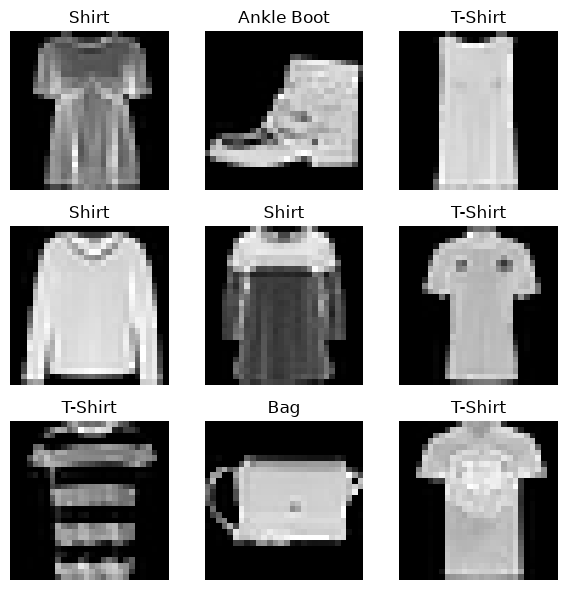

In [8]:
import matplotlib.pyplot as plt

labels_map = {0: "T-Shirt", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
              5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle Boot"}
torch.manual_seed(0)
figure = plt.figure(figsize=(6, 6))
for i in range(1, 10):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(3, 3, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.tight_layout()
plt.show()

A `DataLoader` serves the data in shuffled mini-batches. One batch holds 64 images of shape 1x28x28.

In [9]:
train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


## 3. Transforms

`ToTensor` turns a PIL image into a float tensor and scales the pixels to [0, 1].

In [10]:
raw = datasets.FashionMNIST(root="data", train=True, download=True)
img, label = raw[0]
print("Before:", type(img).__name__, img.size, "pixel range", img.getextrema())
t = ToTensor()(img)
print("After:", t.dtype, tuple(t.shape), f"range [{t.min():.1f}, {t.max():.1f}]")

Before: Image (28, 28) pixel range (0, 255)
After: torch.float32 (1, 28, 28) range [0.0, 1.0]


`Lambda` turns the integer label into a one-hot vector of length 10.

In [11]:
from torchvision.transforms import Lambda

target_transform = Lambda(lambda y: torch.zeros(10, dtype=torch.float).scatter_(0, torch.tensor(y), value=1))
ds = datasets.FashionMNIST(root="data", train=True, download=True,
                           transform=ToTensor(), target_transform=target_transform)
img, one_hot = ds[0]
print("Label", raw[0][1], "->", one_hot)

Label 9 -> tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 1.])


## 4. Build the Neural Network

The network flattens each image to 784 values and passes it through two hidden layers of 512 units with ReLU, ending in 10 outputs (logits).

In [12]:
from torch import nn

class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


Calling the model runs `forward`. Softmax turns the 10 logits into probabilities; the highest one is the prediction (random here, because the model is not trained yet).

In [13]:
X = torch.rand(1, 28, 28, device=device)
logits = model(X)
pred_probab = nn.Softmax(dim=1)(logits)
y_pred = pred_probab.argmax(1)
print(f"Predicted class: {y_pred.item()} ({labels_map[y_pred.item()]})")
print("Probabilities:", pred_probab.detach().cpu().numpy().round(3))

Predicted class: 6 (Shirt)
Probabilities: [[0.095 0.094 0.098 0.101 0.093 0.106 0.111 0.094 0.105 0.104]]


Finally we list the layers' parameters and count them: about 670 thousand weights and biases.

In [14]:
for name, param in model.named_parameters():
    print(f"{name:30s} {str(tuple(param.size())):12s}")
total = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total:,}")

linear_relu_stack.0.weight     (512, 784)  
linear_relu_stack.0.bias       (512,)      
linear_relu_stack.2.weight     (512, 512)  
linear_relu_stack.2.bias       (512,)      
linear_relu_stack.4.weight     (10, 512)   
linear_relu_stack.4.bias       (10,)       
Total parameters: 669,706
